# RBS Library Screening for Biocircuit Design
### Ayush Pandey

In this application example, we show how component contracts can be used to select RBS assignments that satisfy a NAND logic specification.

We consider the transcriptional NAND circuit where inducible promoters $P_{\mathrm{lac}}$ and $P_{\mathrm{BAD}}$ express HrpR and HrpS, respectively. These two regulators jointly activate $P_{\mathrm{hrpL}}$, which leads to the expression of the lambda repressor CI. Since CI represses the reporter, the fluorescence output exhibits a NAND logic behavior. We denote the HrpR and HrpS expression levels by $R$ and $S$, the CI level by $C$, and reporter fluorescence by $G$. The key design choices are to select three RBSs for the circuit, one for each of the two input promoters and one for tuning the CI expression gain $g$.

The data are from [the published study](https://doi.org/10.1038/ncomms1516), for *E. coli* MC1061 in M9 glycerol medium at $30\,{}^\circ\mathrm{C}$.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sympy as sp
from matplotlib.colors import ListedColormap

import biospeak
from biospeak import (
    RBSLibrary,
    derive_modules,
    load_calibration,
    modes,
    verify_library,
)

plt.rcParams.update({"font.size": 16, "pdf.fonttype": 42})
pd.options.display.float_format = "{:.3g}".format

## Equilibrium component interfaces

Regulator binding activates expression in the two input modules. The AND promoter requires occupancy by both HrpR and HrpS to produce CI, and CI binding represses reporter transcription.

Each expression module has transcript and protein dynamics
$$\dot m_i=r_i-\delta_{m,i}m_i,\qquad \dot X_i=k_{\mathrm{tl},i}m_i-\delta_{p,i}X_i,$$
where $r_i$ is the promoter transcription rate, $m_i$ is transcript concentration, $X_i$ is protein concentration, and $k_{\mathrm{tl},i},\delta_{m,i},\delta_{p,i}$ are translation and degradation coefficients. Conserved promoter occupancy states determine the transcription rates.

For independent binding of the two regulators, the equilibrium active AND promoter fraction $a$ and CI expression level satisfy
$$a=\frac{q_Rq_S}{(1+q_R)(1+q_S)},\qquad C=ga.$$
The unoccupied reporter promoter fraction $w$ gives the normalized fluorescence
$$w=\frac{1}{1+q_C},\qquad F=\alpha_G+w,$$
where $q_R=(R/K_R)^{n_R}$, $q_S=(S/K_S)^{n_S}$, $q_C=(C/K_C)^{n_C}$ are normalized regulatory activities. The thresholds $K_R,K_S,K_C$ and exponents $n_R,n_S,n_C$ describe the AND and repression activity maps. The coefficient $\alpha_G$ is basal transcription.

In [2]:
modules = derive_modules()
for name, module in modules.items():
    print(name)
    display(sp.Eq(sp.Symbol("output"), module.normalized))

activation


Eq(output, (alpha*q + alpha + q)/(q + 1))

and_occupancy


Eq(output, q_R*q_S/((q_R + 1)*(q_S + 1)))

not_occupancy


Eq(output, (alpha*q_C + alpha + 1)/(q_C + 1))

## Calibration

We relate inducer concentrations and expression levels to regulatory activities using the fitted relations
$$X_i(I_i)=k_i\left(\alpha_i+\frac{(I_i/K_{Ii})^{\nu_i}}{1+(I_i/K_{Ii})^{\nu_i}}\right),$$
where $I_1,I_2$ are IPTG and arabinose in mM. The parameters $k_i,K_{Ii},\nu_i,\alpha_i$ are the input response amplitude, inducer threshold, Hill exponent, and basal coefficient, respectively.

In [3]:
promoters, gate, repressors = load_calibration()
pR, pS = promoters["Plac_rbsH_30C"], promoters["PBAD_rbs33_30C"]
repressor = repressors["rbs34"]
constructor = RBSLibrary(modules, gate, repressor)
selected_modes = modes()
pd.DataFrame([vars(pR), vars(pS)])

,id,k,K,n,alpha,rbs,promoter
0,Plac_rbsH_30C,2.07e+03,0.287,1.28,0.0037,rbsH,Plac
1,PBAD_rbs33_30C,1.29e+04,0.513,1.32,0.0013,rbs33,PBAD


## Specification and CI expression gain

We require $F\leq0.20$ in OFF and $F\geq0.80$ in ON1 and ON2, with
$$\begin{aligned}
a_{\mathrm{OFF}}&:[0.40,1.6]\times[0.33,1.3],\\
a_{\mathrm{ON1}}&:[0,0.0016]\times[0.33,1.3],\\
a_{\mathrm{ON2}}&:[0.40,1.6]\times[0,0.0052].
\end{aligned}$$
The OFF requirement gives a lower bound on $g$, and the ON1 and ON2 requirements give upper bounds. A sufficient gain satisfies
$$\frac{C_*(0.20)}{a_{\mathrm{OFF}}^-}\leq g\leq
\min_{m\in\{\mathrm{ON1},\mathrm{ON2}\}}\frac{C_*(0.80)}{a_m^+},$$
where $C_*(F_*)=K_C(1/(F_*-\alpha_G)-1)^{1/n_C}$.

In [4]:
gain_requirement = constructor.required_gain(pR, pS, selected_modes)
gain = 17944.802603618242
assert gain_requirement["lower"] <= gain <= gain_requirement["upper"]
pd.DataFrame(
    [
        dict(
            lower=gain_requirement["lower"],
            gain=gain,
            upper=gain_requirement["upper"],
            relative_gain=gain / repressor.K,
        )
    ]
)

,lower,gain,upper,relative_gain
0,1.01e+03,1.79e+04,3.14e+05,48.8


## Contract construction and verification

On each required input region, monotonicity of the calibrated promoter responses gives expression bounds. These extrema set up the intervals for the input assumptions of the AND contract. The CI expression balance then gives the input bounds for the repression contract. Thus, each RBS assignment has component contracts constructed from its own calibrated expression ranges.

In [5]:
reference = {
    mode.name: constructor.construct(pR, pS, mode, gain) for mode in selected_modes
}
assert all(result["status"] == "certified" for result in reference.values())
pd.DataFrame(
    [
        dict(
            mode=mode,
            lower=result["fluorescence_interval"][0],
            upper=result["fluorescence_interval"][1],
            status=result["status"],
        )
        for mode, result in reference.items()
    ]
)

,mode,lower,upper,status
0,OFF,0.0509,0.0509,certified
1,ON1,1.05,1.05,certified
2,ON2,1.05,1.05,certified


## Formal library screening

We construct and compose contracts using the calibrated promoter activity ranges for each RBS choice in the RBS library. The library comprises 30 assignments from five usable $P_{\mathrm{lac}}$ calibrations and six $P_{\mathrm{BAD}}$ calibrations.

In [6]:
library, certificates = verify_library(constructor, promoters, selected_modes, gain)
screen = pd.DataFrame(library)
assert screen["contract"].value_counts().to_dict() == {
    "violated": 16,
    "certified": 7,
    "unknown": 7,
}
screen[["R_RBS", "S_RBS", "contract"]]

,R_RBS,S_RBS,contract
0,rbs30,rbs30,violated
1,rbs30,rbs31,violated
2,rbs30,rbs32,certified
3,rbs30,rbs33,certified
4,rbs30,rbs34,violated
5,rbs30,rbsH,unknown
6,rbs31,rbs30,violated
7,rbs31,rbs31,violated
8,rbs31,rbs32,violated
9,rbs31,rbs33,violated


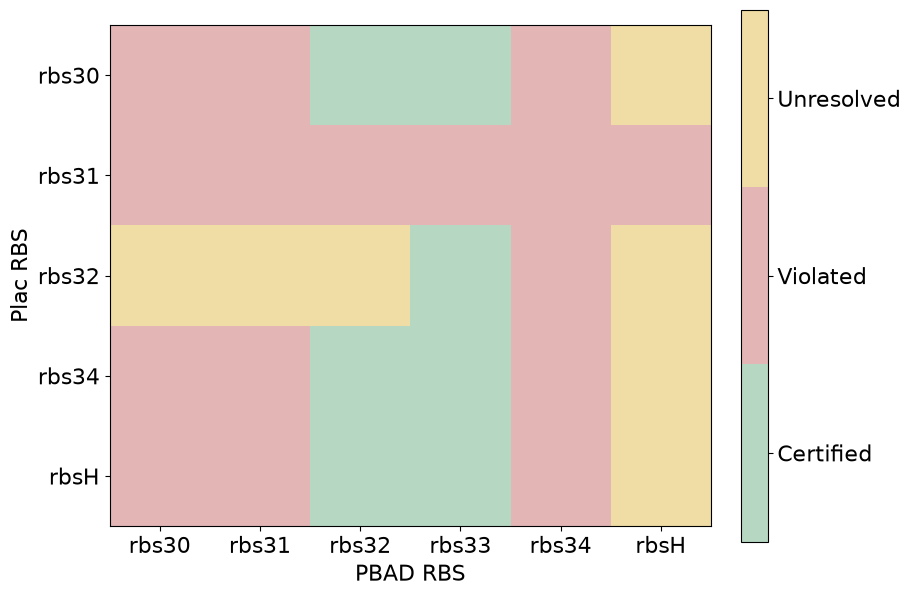

In [7]:
matrix = screen.pivot(index="R_RBS", columns="S_RBS", values="contract")
colors = {"certified": 0, "violated": 1, "unknown": 2}
values = np.array([[colors[value] for value in row] for row in matrix.to_numpy()])
fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")
image = ax.imshow(
    values, cmap=ListedColormap(["#b6d8c3", "#e3b5b5", "#f0dda5"]), vmin=-0.5, vmax=2.5
)
ax.set(
    xticks=np.arange(len(matrix.columns)),
    xticklabels=matrix.columns,
    yticks=np.arange(len(matrix.index)),
    yticklabels=matrix.index,
    xlabel="PBAD RBS",
    ylabel="Plac RBS",
)
colorbar = fig.colorbar(image, ax=ax, ticks=[0, 1, 2])
colorbar.ax.set_yticklabels(["Certified", "Violated", "Unresolved"])
plt.show()

## Comparison with published data

We compare the calibrated equilibrium model response and the composed contract bounds for the reference RBS assignment with the published response of the assembled NAND circuit. We use the mean fluorescence values from Figure 5(c). We normalize the model predictions and contract bounds by the maximum model value to compare relative fluorescence with the published circuit response.

In [8]:
data_path = Path(biospeak.__file__).parent / "data" / "rbs"
observations = pd.read_csv(data_path / "figure5c_boundary_observations.csv")
model_max = float(constructor.fluorescence(pR, pS, 0, 0, gain))
prediction = (
    constructor.fluorescence(
        pR,
        pS,
        observations.IPTG_mM.to_numpy(),
        observations.arabinose_mM.to_numpy(),
        gain,
    )
    / model_max
)
observations["prediction"] = prediction
correlation = np.corrcoef(prediction, observations.observed_relative)[0, 1]
print(f"Pearson correlation: {correlation:.3f}")
assert np.isclose(correlation, 0.893, atol=0.001)

Pearson correlation: 0.893


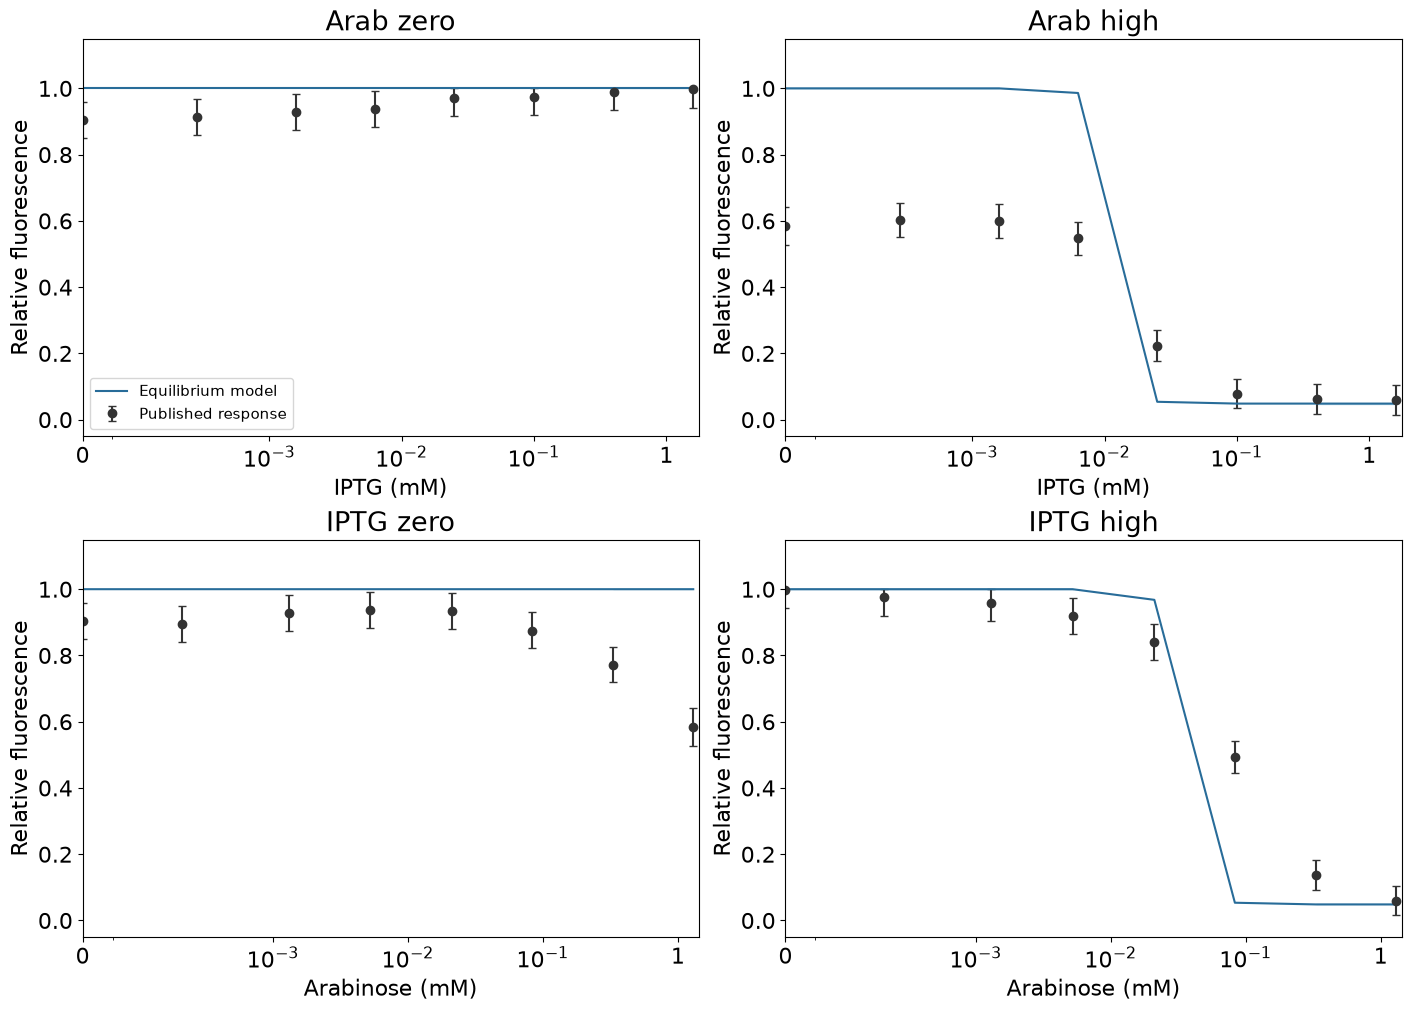

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), layout="constrained")
for ax, edge in zip(axes.ravel(), ["Arab_zero", "Arab_high", "IPTG_zero", "IPTG_high"]):
    varying = "IPTG_mM" if edge.startswith("Arab") else "arabinose_mM"
    frame = observations[observations.edge.str.contains(edge)].sort_values(varying)
    x = frame[varying].to_numpy()
    ax.errorbar(
        x,
        frame.observed_relative,
        yerr=[
            frame.observed_relative - frame.graphical_lower,
            frame.graphical_upper - frame.observed_relative,
        ],
        fmt="o",
        capsize=3,
        color="0.2",
        label="Published response",
    )
    ax.plot(x, frame.prediction, color="#286c99", label="Equilibrium model")
    for mode in selected_modes:
        selected = frame.IPTG_mM.between(*mode.I1) & frame.arabinose_mM.between(
            *mode.I2
        )
        domain = frame.loc[selected, varying].to_numpy()
        if len(domain):
            lower, upper = (
                np.array(reference[mode.name]["fluorescence_interval"]) / model_max
            )
            ax.fill_between(domain, lower, upper, color="#91c3df", alpha=0.6)
    ax.set(
        xlabel="IPTG (mM)" if varying == "IPTG_mM" else "Arabinose (mM)",
        ylabel="Relative fluorescence",
        title=edge.replace("_", " "),
        ylim=(-0.05, 1.15),
    )
    ax.set_xscale("symlog", linthresh=0.0005)
    ax.set_xlim(0, max(x) * 1.1)
    ax.set_xticks(
        [0, 0.001, 0.01, 0.1, 1], ["0", r"$10^{-3}$", r"$10^{-2}$", r"$10^{-1}$", "1"]
    )
axes[0, 0].legend(fontsize=11)
plt.show()